# Fase 2 · De reservas originales a modelos de referencia

**Objetivo:** preparar Hotel Booking Demand y establecer referencias reproducibles para cancelación y ADR, siguiendo la sección **3.2** de la guía. La unidad es una reserva, no un huésped. Conservamos el proyecto/script previo: este cuaderno contiene todo su código necesario, sin importar `src` ni ejecutar la CLI.

**Recorrido:** entorno → fuente y calidad → limpieza → variables → partición/desbalance → transformaciones → cuatro baselines → evaluación → exportación y límites. No repetimos el EDA exhaustivo de fase 1 ni adelantamos modelos de fase 3/dashboard.

La fotografía es del **día previo a la llegada**, no del alta de la reserva. La clasificación es retrospectiva; ADR es transacciones de alojamiento/noches, **no una cotización inicial**. No se interpretan asociaciones como causalidad.

## 1. Entorno y configuración

Python **3.14**, un único entorno uv. Desde `preprocesamiento`, instalar `uv sync --frozen --group notebook`. El grupo opcional añade solamente ejecución/kernel/formato de notebook; no hace falta para las pruebas offline. Reiniciar el kernel y ejecutar todas las celdas en orden. El README contiene un comando probado con la API `NotebookClient`.

Modificar aquí la semilla o las rutas. Se reconoce la raíz del repositorio por el directorio `preprocesamiento`; en una carpeta autónoma se usa el directorio actual. **No se requiere `src`, informe ni salidas anteriores**. Los destinos nuevos evitan sobrescribir artefactos canónicos. Las rutas relativas se interpretan respecto a `root`.

In [1]:
import hashlib
import json
import math
import shutil
import sys
from datetime import UTC, datetime
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
    root_mean_squared_error,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

assert sys.version_info[:2] == (3, 14), "Python 3.14 kernel required"

SEED = 42
root = Path.cwd()
if (root / "preprocesamiento").is_dir():
    root = root / "preprocesamiento"
raw_dir = root / "data/raw"
output_dir = root / "outputs/notebook_phase2"
processed_dir = root / "data/processed/notebook_phase2"
if (
    output_dir.resolve() == (root / "outputs").resolve()
    or processed_dir.resolve() == (root / "data/processed").resolve()
):
    raise ValueError("Use separate notebook destinations, not canonical directories")
pl.Config.set_tbl_rows(12)
pl.Config.set_tbl_cols(9)
pl.Config.set_fmt_str_lengths(32)
print(f"Python {sys.version.split()[0]} · seed={SEED}")

Python 3.14.6 · seed=42


## 2. Fuente, carga y validación

Fuente: [Kaggle, Jesse Mostipak](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand), a partir de António, de Almeida y Nunes (2019), [DOI 10.1016/j.dib.2018.11.126](https://doi.org/10.1016/j.dib.2018.11.126). Licencia **CC BY 4.0**: conservar atribución.

El CSV público combinado tiene **119390 × 32**. `agent` y `company` son identificadores nominales, no magnitudes. Validamos nombres/tipos y target binario. La función lectora admite fixtures pequeños; la adquisición real exige las dimensiones públicas. Si el CSV ya existe, **no se descarga ni reescribe**; si falta, Kagglehub obtiene el original. Un error no se reemplaza con datos ficticios. Se registra inspección local/hash, nunca una fecha de descarga no acreditada.

In [2]:
COLUMNS = [
    "hotel",
    "is_canceled",
    "lead_time",
    "arrival_date_year",
    "arrival_date_month",
    "arrival_date_week_number",
    "arrival_date_day_of_month",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "meal",
    "country",
    "market_segment",
    "distribution_channel",
    "is_repeated_guest",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "reserved_room_type",
    "assigned_room_type",
    "booking_changes",
    "deposit_type",
    "agent",
    "company",
    "days_in_waiting_list",
    "customer_type",
    "adr",
    "required_car_parking_spaces",
    "total_of_special_requests",
    "reservation_status",
    "reservation_status_date",
]

CATEGORICAL = [
    "hotel",
    "arrival_date_month",
    "meal",
    "country",
    "market_segment",
    "distribution_channel",
    "is_repeated_guest",
    "reserved_room_type",
    "assigned_room_type",
    "deposit_type",
    "agent",
    "company",
    "customer_type",
    "reservation_status",
    "is_canceled",
]

STRINGS = set(CATEGORICAL) - {"is_canceled", "is_repeated_guest"} | {
    "reservation_status_date"
}

SCHEMA = {
    name: pl.String
    if name in STRINGS
    else pl.Float64
    if name in {"children", "adr"}
    else pl.Int64
    for name in COLUMNS
}

DATASET = "jessemostipak/hotel-booking-demand"

In [3]:
def read_bookings(path: Path) -> pl.DataFrame:
    "Lee el esquema original de 32 columnas y valida el objetivo binario."
    names = pl.read_csv(path, n_rows=0).schema
    if set(names) != set(COLUMNS):
        raise ValueError("Expected 32 columns matching Hotel Booking Demand schema")
    frame = pl.read_csv(
        path,
        schema_overrides=SCHEMA,
        null_values=["NULL", "NA", ""],
        infer_schema_length=10000,
    )
    if frame.is_empty():
        raise ValueError("Dataset must contain bookings")
    if (
        not set(frame["is_canceled"].drop_nulls().unique()) <= {0, 1}
        or frame["is_canceled"].null_count()
    ):
        raise ValueError("is_canceled must contain only 0 and 1")
    return frame.select(COLUMNS)

In [4]:
def write_json(path: Path, data: object) -> None:
    "Escribe JSON legible y convierte valores no finitos a nulos explícitos."

    def sanitize(value):
        """Normaliza recursivamente escalares, listas y diccionarios para JSON."""
        if isinstance(value, dict):
            return {str(key): sanitize(item) for key, item in value.items()}
        if isinstance(value, (list, tuple)):
            return [sanitize(item) for item in value]
        if isinstance(value, float) and not math.isfinite(value):
            return None
        if hasattr(value, "item"):
            return sanitize(value.item())
        return value

    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(
        json.dumps(sanitize(data), indent=2, ensure_ascii=False, allow_nan=False),
        encoding="utf-8",
    )


def prepare(raw_dir: Path, output_dir: Path) -> pl.DataFrame:
    "Reutiliza el CSV intacto o lo adquiere con Kagglehub y registra procedencia."
    path = raw_dir / "hotel_bookings.csv"
    source_metadata = output_dir / "source.json"
    prior = (
        json.loads(source_metadata.read_text(encoding="utf-8"))
        if source_metadata.exists()
        else {}
    )
    acquisition = prior.get(
        "acquisition",
        {
            "obtained_at_utc": datetime.now(UTC).isoformat(),
            "origin": "local_cached" if path.exists() else "pending",
            "downloaded_at_utc": None,
            "local_file_modified_at_utc": datetime.fromtimestamp(
                path.stat().st_mtime, UTC
            ).isoformat()
            if path.exists()
            else None,
            "meaning": "Local acquisition/inspection recorded now; original download timestamp was not captured and remains unknown. Filesystem modification is not proof of network download.",
        },
    )
    if not path.exists():
        import kagglehub

        try:
            source = Path(kagglehub.dataset_download(DATASET)) / path.name
            raw_dir.mkdir(parents=True, exist_ok=True)
            shutil.copyfile(source, path)
            acquisition = {
                "obtained_at_utc": datetime.now(UTC).isoformat(),
                "origin": "kagglehub_cache_or_download",
                "downloaded_at_utc": None,
                "method": "kagglehub.dataset_download (may reuse Kaggle cache), then local original copy",
                "kaggle_cache_version": source.parent.name,
            }
        except Exception as exc:
            raise RuntimeError(f"Kaggle download failed for {DATASET}: {exc}") from exc
    frame = read_bookings(path)
    if frame.shape != (119390, 32):
        raise ValueError(f"Unexpected public dataset dimensions: {frame.shape}")
    write_json(
        output_dir / "source.json",
        {
            "dataset": DATASET,
            "acquisition": acquisition,
            "license": "CC BY 4.0, independently verified Kaggle and Antonio et al.; see specification.md",
            "attribution": "Antonio, de Almeida and Nunes (2019), DOI 10.1016/j.dib.2018.11.126; Kaggle redistributor Jesse Mostipak",
            "kaggle_version": 1,
            "url": f"https://www.kaggle.com/datasets/{DATASET}",
            "verified_at_utc": datetime.now(UTC).isoformat(),
            "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
            "rows": frame.height,
            "columns": frame.width,
            "schema": {key: str(value) for key, value in frame.schema.items()},
        },
    )
    return frame

In [5]:
raw = prepare(raw_dir, output_dir)
raw_hash = hashlib.sha256((raw_dir / "hotel_bookings.csv").read_bytes()).hexdigest()
print(f"Original: {raw.height} reservas × {raw.width} columnas")
print(f"SHA-256: {raw_hash}")
print(raw.select("hotel", "is_canceled", "adults", "children", "adr").head(5))

Original: 119390 reservas × 32 columnas
SHA-256: 7c2ae42a7353905ea136e5c2287f17c92c5435826598bfbb8491c6f0c7b1fc06
shape: (5, 5)
┌──────────────┬─────────────┬────────┬──────────┬──────┐
│ hotel        ┆ is_canceled ┆ adults ┆ children ┆ adr  │
│ ---          ┆ ---         ┆ ---    ┆ ---      ┆ ---  │
│ str          ┆ i64         ┆ i64    ┆ f64      ┆ f64  │
╞══════════════╪═════════════╪════════╪══════════╪══════╡
│ Resort Hotel ┆ 0           ┆ 2      ┆ 0.0      ┆ 0.0  │
│ Resort Hotel ┆ 0           ┆ 2      ┆ 0.0      ┆ 0.0  │
│ Resort Hotel ┆ 0           ┆ 1      ┆ 0.0      ┆ 75.0 │
│ Resort Hotel ┆ 0           ┆ 1      ┆ 0.0      ┆ 75.0 │
│ Resort Hotel ┆ 0           ┆ 2      ┆ 0.0      ┆ 98.0 │
└──────────────┴─────────────┴────────┴──────────┴──────┘


## 3. Diagnóstico de calidad antes de imputar

**MCAR**: ausencia independiente de valores observados/no observados. **MAR**: dependiente de covariables observadas. **MNAR**: depende del propio valor desconocido aun condicionando por las observadas. Las tasas por hotel, cancelación y segmento permiten explorar diferencias; **no prueban ni descartan por sí solas ninguno de los mecanismos**. Los cuatro niños desconocidos del CSV actual se concentran en canceladas del hotel urbano: MAR es plausible, MNAR no se excluye; no afirmamos MCAR demostrado ni rechazo formal.

`agent/company` NULL es **no aplicable** según la fuente, no un número para imputar. Se excluyen del baseline; `country` también por disponibilidad incierta al check-in. Para `children`, mediana de train: robusta y sencilla ante pocos faltantes. Eliminar esas reservas perdería adultos conocidos; KNN/Iterative añadirían supuestos y complejidad sin evidencia de mejora. No se ajusta todavía ninguna imputación.

IQR es una **bandera exploratoria** sobre el original, no un umbral aprendido para filtrar holdouts. Mostramos también repetidos; una fila idéntica puede ser otra reserva real y no se elimina.

In [6]:
def quality_diagnostics(frame: pl.DataFrame) -> dict:
    """Resume ausencia condicionada, repetidos y colas sin modificar las reservas."""
    missing = {
        name: {
            "count": frame[name].null_count(),
            "percent": 100 * frame[name].null_count() / frame.height,
        }
        for name in COLUMNS
    }
    absence = {
        name: {
            group: frame.group_by(group)
            .agg(
                pl.len().alias("rows"),
                pl.col(name).is_null().sum().alias("missing"),
                (100 * pl.col(name).is_null().mean()).alias("missing_percent"),
            )
            .sort(group)
            .to_dicts()
            for group in ["hotel", "is_canceled", "market_segment"]
        }
        for name in COLUMNS
        if missing[name]["count"]
    }
    q1 = frame["adr"].quantile(0.25, interpolation="linear")
    q3 = frame["adr"].quantile(0.75, interpolation="linear")
    assert q1 is not None and q3 is not None
    lower, upper = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    return {
        "missing": missing,
        "missingness_by_group": absence,
        "duplicates_extra": frame.height - frame.unique().height,
        "duplicate_member_rows": int(frame.is_duplicated().sum()),
        "adr_iqr": {
            "lower": lower,
            "upper": upper,
            "below": frame.filter(pl.col("adr") < lower).height,
            "above": frame.filter(pl.col("adr") > upper).height,
            "zero": frame.filter(pl.col("adr") == 0).height,
        },
    }


quality = quality_diagnostics(raw)
print(
    pl.DataFrame(
        [
            {"variable": name, **item}
            for name, item in quality["missing"].items()
            if item["count"]
        ]
    )
)
print("Ausencia de niños por hotel:")
print(pl.DataFrame(quality["missingness_by_group"]["children"]["hotel"]))
print("Ausencia de niños por cancelación:")
print(pl.DataFrame(quality["missingness_by_group"]["children"]["is_canceled"]))
print(
    {
        key: value
        for key, value in quality.items()
        if key not in {"missing", "missingness_by_group"}
    }
)
write_json(output_dir / "quality.json", quality)

shape: (4, 3)
┌──────────┬────────┬───────────┐
│ variable ┆ count  ┆ percent   │
│ ---      ┆ ---    ┆ ---       │
│ str      ┆ i64    ┆ f64       │
╞══════════╪════════╪═══════════╡
│ children ┆ 4      ┆ 0.00335   │
│ country  ┆ 488    ┆ 0.408744  │
│ agent    ┆ 16340  ┆ 13.686238 │
│ company  ┆ 112593 ┆ 94.306893 │
└──────────┴────────┴───────────┘
Ausencia de niños por hotel:
shape: (2, 4)
┌──────────────┬───────┬─────────┬─────────────────┐
│ hotel        ┆ rows  ┆ missing ┆ missing_percent │
│ ---          ┆ ---   ┆ ---     ┆ ---             │
│ str          ┆ i64   ┆ i64     ┆ f64             │
╞══════════════╪═══════╪═════════╪═════════════════╡
│ City Hotel   ┆ 79330 ┆ 4       ┆ 0.005042        │
│ Resort Hotel ┆ 40060 ┆ 0       ┆ 0.0             │
└──────────────┴───────┴─────────┴─────────────────┘
Ausencia de niños por cancelación:
shape: (2, 4)
┌─────────────┬───────┬─────────┬─────────────────┐
│ is_canceled ┆ rows  ┆ missing ┆ missing_percent │
│ ---         ┆ ---   ┆ --

## 4. Limpieza trazable y tratamiento de extremos

| Regla de dominio | Decisión y motivo |
|---|---|
| ADR negativo o no finito/ausente | Excluir de esta población; no atribuir automáticamente error al original |
| Conteos negativos | Excluir por incoherencia de cantidades |
| Sin huéspedes conocidos o sin noches | Excluir del baseline de estancias con ocupación |
| ADR cero | Conservar: puede representar cortesía |
| Extremo positivo finito | Conservar: puede ser demanda real; IQR no demuestra error |
| Repetidos exactos | Conservar juntos en una partición, no deduplicar |

La remoción razonada se aplica a inválidos de dominio, **no a toda la cola IQR**. Logaritmo o winsorización cambiarían objetivo/colas; no se eligen por resultados de test. Esta retención mantiene sensibilidad de RMSE a extremos como limitación explícita.

Primero asignamos `row_id` y huella sobre las **32 columnas originales**, antes de transformar. Las reglas pueden solaparse: su suma no es el número de descartes distintos. El JSON enumera cada `row_id` rechazado y sus motivos, sin imprimir esa lista masiva.

In [7]:
def clean_bookings(frame: pl.DataFrame) -> tuple[pl.DataFrame, dict]:
    "Conserva huellas/repetidos y deriva variables; excluye reglas de dominio con auditoría."
    # La huella precede toda transformación: las reservas repetidas se conservan juntas.
    frame = frame.with_columns(
        pl.struct(COLUMNS).hash(seed=42).alias("original_fingerprint")
    ).with_row_index("row_id")
    frame = frame.with_columns(
        (pl.col("stays_in_weekend_nights") + pl.col("stays_in_week_nights")).alias(
            "total_nights"
        ),
        (pl.col("adults") + pl.col("children") + pl.col("babies")).alias(
            "total_guests"
        ),
    )
    rules = {
        "negative_adr": pl.col("adr") < 0,
        "negative_counts": pl.any_horizontal(
            pl.col(name) < 0
            for name in [
                "adults",
                "children",
                "babies",
                "stays_in_weekend_nights",
                "stays_in_week_nights",
                "lead_time",
            ]
        ),
        "zero_guests": (
            pl.col("adults") + pl.col("children").fill_null(0) + pl.col("babies")
        )
        == 0,
        "zero_nights": pl.col("total_nights") == 0,
        "missing_target": pl.col("adr").is_null() | ~pl.col("adr").is_finite(),
    }
    frame = frame.with_columns(
        [expr.fill_null(False).alias(f"invalid_{name}") for name, expr in rules.items()]
    )
    invalid = pl.any_horizontal(pl.col(f"invalid_{name}") for name in rules)
    rejected = frame.filter(invalid)
    cleaned = frame.filter(~invalid)
    return cleaned, {
        "input_rows": frame.height,
        "retained_rows": cleaned.height,
        "removed_rows": rejected.height,
        "rules": {name: int(frame[f"invalid_{name}"].sum()) for name in rules},
        "rejected": rejected.select(
            "row_id", "original_fingerprint", *[f"invalid_{name}" for name in rules]
        ).to_dicts(),
        "policy": "Keep duplicates, zero ADR and finite positive extremes; exclude negative ADR, negative counts, zero known guests and zero nights. Missing children remain unknown; train-only median imputation. IQR tails may represent real demand: retain rather than data-dependent trimming; log/winsorization are alternatives not tuned on test.",
    }

In [8]:
cleaned, audit = clean_bookings(raw)
processed_dir.mkdir(parents=True, exist_ok=True)
cleaned.write_parquet(processed_dir / "cleaned.parquet")
write_json(output_dir / "cleaning.json", audit)
print(
    pl.DataFrame(
        [
            {"rule": name, "flagged_rows": count}
            for name, count in audit["rules"].items()
        ]
    )
)
print(f"Descartes distintos: {audit['removed_rows']} · retenidas: {cleaned.height}")
assert raw.height == cleaned.height + audit["removed_rows"]

shape: (5, 2)
┌─────────────────┬──────────────┐
│ rule            ┆ flagged_rows │
│ ---             ┆ ---          │
│ str             ┆ i64          │
╞═════════════════╪══════════════╡
│ negative_adr    ┆ 1            │
│ negative_counts ┆ 0            │
│ zero_guests     ┆ 180          │
│ zero_nights     ┆ 715          │
│ missing_target  ┆ 0            │
└─────────────────┴──────────────┘
Descartes distintos: 826 · retenidas: 118564


## 5. Variables derivadas, tareas y temporalidad

- `total_nights = stays_in_weekend_nights + stays_in_week_nights`: duración total; entra en X **en lugar** de sus componentes.
- `total_guests = adults + children + babies`: tamaño del grupo; si niños es desconocido, el total también. Se guarda para trazabilidad, **no entra en X ni se imputa por separado**. X conserva adultos/niños/bebés: así tres adultos conocidos no se convierten en una mediana de dos huéspedes (regresión H1).

| Tarea | Población y objetivo | Exclusiones de X |
|---|---|---|
| Clasificación retrospectiva | Todas las reservas limpias; `is_canceled` | ADR y todo desenlace |
| Regresión | Solo no canceladas; `adr` | `is_canceled` y ADR |

Excluimos estado y fecha de estado (resultado), habitación asignada (operación), cambios y espera (acumulados), depósito (pagos antes de llegada **o cancelación**), parking y solicitudes (sin timestamp), país (puede conocerse al check-in), IDs de agencia/empresa y componentes de calendario redundantes (año/semana/día). Mes es nominal cíclico, no magnitud ordinal. Conservamos antecedentes, hotel, canal, segmento y habitación reservada como aproximación conservadora; esto **no garantiza disponibilidad al crear reserva**.

Full One-Hot con intercepto es redundante: mínimos cuadrados/SVD no habilita inferencia de coeficientes. No añadimos suma exacta de huéspedes a sus componentes.

In [9]:
def feature_columns(task: str) -> tuple[list[str], list[str]]:
    "Devuelve predictores conservadores para cada tarea y rechaza tareas desconocidas."
    if task not in {"classification", "regression"}:
        raise ValueError("Unknown task")
    return [
        "lead_time",
        "adults",
        "children",
        "babies",
        "total_nights",
        "previous_cancellations",
        "previous_bookings_not_canceled",
    ], [
        "hotel",
        "arrival_date_month",
        "meal",
        "market_segment",
        "distribution_channel",
        "is_repeated_guest",
        "reserved_room_type",
        "customer_type",
    ]


for task in ["classification", "regression"]:
    numeric, categorical = feature_columns(task)
    print(f"{task}: numéricas={numeric}; nominales={categorical}")
print(
    cleaned.select("adults", "children", "babies", "total_guests", "total_nights").head(
        5
    )
)

classification: numéricas=['lead_time', 'adults', 'children', 'babies', 'total_nights', 'previous_cancellations', 'previous_bookings_not_canceled']; nominales=['hotel', 'arrival_date_month', 'meal', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'reserved_room_type', 'customer_type']
regression: numéricas=['lead_time', 'adults', 'children', 'babies', 'total_nights', 'previous_cancellations', 'previous_bookings_not_canceled']; nominales=['hotel', 'arrival_date_month', 'meal', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'reserved_room_type', 'customer_type']
shape: (5, 5)
┌────────┬──────────┬────────┬──────────────┬──────────────┐
│ adults ┆ children ┆ babies ┆ total_guests ┆ total_nights │
│ ---    ┆ ---      ┆ ---    ┆ ---          ┆ ---          │
│ i64    ┆ f64      ┆ i64    ┆ f64          ┆ i64          │
╞════════╪══════════╪════════╪══════════════╪══════════════╡
│ 1      ┆ 0.0      ┆ 0      ┆ 1.0          ┆ 1            │
│ 1      ┆ 0.0      ┆ 

## 6. Partición por filas, grupos y desbalance

Dividimos **antes de fit**: objetivo 75/12.5/12.5 % de **filas**, no de grupos. En clasificación se reparte dentro de cada clase (estratificación ponderada). Una huella original íntegra va a un solo split. Los grupos grandes se ordenan primero; desempates reproducibles por semilla. Se asigna al mayor **déficit relativo** donde cabe; si ninguno encaja, se minimiza el aumento de error relativo cuadrático. Así no enviamos todos los repetidos a train (regresión H2).

Se valida 70–80 % de filas train y holdouts no vacíos **antes de entrenar/exportar**. En clasificación se exigen ambas clases (0 y 1) en la población y al menos tres grupos originales distintos por clase: es una condición necesaria, no suficiente. Tras asignar, se comprueba que **cada split contiene ambas clases**, antes de cualquier fit o exportación; si falla se rechaza el resultado del heurístico, sin afirmar que no exista otra solución. Estas restricciones de clases no se aplican a regresión. Los grupos indivisibles pueden impedir proporciones exactas; esta heurística voraz no es un solver exhaustivo: ante incompatibilidad detectada rechaza explícitamente.

El desbalance se mide **solo en train**. Minoría <10 % activa `class_weight="balanced"` en logística; de otro modo no remuestreamos. No aplicamos SMOTE por rutina. Con el CSV actual la prevalencia es aproximadamente 37.26 %, no severa.

Los perfiles X compartidos se diagnostican aparte: distintas reservas pueden compartir predictores conservadores; no se fusionan borrando el target. Huellas distintas no prueban independencia de cliente/grupo comercial; un hash tiene riesgo de colisión no nulo.

In [10]:
def split_bookings(
    frame: pl.DataFrame, classification: bool = False
) -> dict[str, pl.DataFrame]:
    "Asigna grupos íntegros por peso de filas y clase; valida proporciones antes de continuar."
    # Repartir por filas de cada clase, sin romper las huellas ni eliminar reservas.
    groups = frame.group_by("original_fingerprint", maintain_order=True).agg(
        pl.col("is_canceled").first(), pl.len().alias("weight")
    )
    target_classes = set(frame["is_canceled"])
    if classification and target_classes != {0, 1}:
        raise ValueError(
            f"Classification requires both target classes [0, 1]; observed {sorted(target_classes)}"
        )
    largest = int(groups["weight"].to_numpy().max()) if groups.height else 0
    if frame.is_empty() or largest > 0.80 * frame.height:
        raise ValueError(
            f"Cannot satisfy train row fraction 70%-80% with intact original groups: largest group {largest}, total rows {frame.height}"
        )
    if classification:
        for label in sorted(target_classes):
            count = groups.filter(pl.col("is_canceled") == label).height
            if count < 3:
                raise ValueError(
                    f"Cannot stratify three splits with intact original groups: class {label} has {count} original groups; at least 3 required"
                )
    groups = groups.with_columns(
        pl.Series("tie_break", np.random.default_rng(SEED).random(groups.height))
    ).sort(["weight", "tie_break"], descending=[True, False])
    weights_by_class = {}
    for row in groups.iter_rows(named=True):
        label = row["is_canceled"] if classification else 0
        weights_by_class[label] = weights_by_class.get(label, 0) + row["weight"]
    fractions = np.array([0.75, 0.125, 0.125])
    targets = {label: fractions * weight for label, weight in weights_by_class.items()}
    assigned = {label: np.zeros(3, dtype=np.int64) for label in targets}
    fingerprints = [[], [], []]
    for row in groups.iter_rows(named=True):
        label = row["is_canceled"] if classification else 0
        target = targets[label]
        remaining = target - assigned[label]
        fitting = [index for index in range(3) if row["weight"] <= remaining[index]]
        if fitting:
            # Déficit relativo: no agotar los grupos repetidos solo en entrenamiento.
            destination = max(
                fitting,
                key=lambda index: (
                    remaining[index] / target[index],
                    target[index],
                    -index,
                ),
            )
        else:
            # Sin encaje exacto, minimizar el aumento del error relativo cuadrático.
            relative_error = (assigned[label] - target) / target
            increase = (
                (assigned[label] + row["weight"] - target) / target
            ) ** 2 - relative_error**2
            destination = min(
                range(3), key=lambda index: (increase[index], -target[index], index)
            )
        fingerprints[destination].append(row["original_fingerprint"])
        assigned[label][destination] += row["weight"]
    parts = {
        name: frame.filter(
            pl.col("original_fingerprint").is_in(
                pl.Series(
                    fingerprints[index], dtype=frame.schema["original_fingerprint"]
                ).implode()
            )
        )
        for index, name in enumerate(["train", "validation", "test"])
    }
    train_fraction = parts["train"].height / frame.height
    if not 0.70 <= train_fraction <= 0.80 or any(
        part.is_empty() for part in parts.values()
    ):
        raise ValueError(
            f"Cannot satisfy train row fraction 70%-80% and nonempty holdouts using weighted greedy assignment: train fraction {train_fraction:.6f}, largest group {largest}, total rows {frame.height}"
        )
    if classification:
        observed_classes = {
            name: sorted(set(part["is_canceled"])) for name, part in parts.items()
        }
        if any(set(labels) != target_classes for labels in observed_classes.values()):
            raise ValueError(
                f"Weighted greedy assignment did not preserve all target classes in every split: expected {sorted(target_classes)}, observed {observed_classes}; heuristic result rejected, not an exhaustive feasibility verdict"
            )
    return parts

In [11]:
def group_size_summary(frame: pl.DataFrame) -> dict:
    "Resume tamaños de grupos originales y masa de filas repetidas para auditar splits."
    sizes = frame.group_by("original_fingerprint").len(name="size")
    weights = sizes["size"].to_numpy()
    repeated = weights[weights > 1]
    return {
        "groups": len(weights),
        "singleton_groups": int((weights == 1).sum()),
        "repeated_groups": len(repeated),
        "rows_in_repeated_groups": int(repeated.sum()),
        "fraction_rows_in_repeated_groups": float(repeated.sum() / frame.height),
        "min": int(weights.min()),
        "median": float(np.median(weights)),
        "max": int(weights.max()),
        "histogram": sizes.group_by("size")
        .len(name="groups")
        .with_columns((pl.col("size") * pl.col("groups")).alias("rows"))
        .sort("size")
        .to_dicts(),
    }

## 7. Transformaciones ajustadas únicamente en train

`Pipeline(preprocess, model)` contiene un `ColumnTransformer`: rama numérica **mediana → StandardScaler**; rama nominal **imputación moda → OneHotEncoder(handle_unknown="ignore")**. El adaptador nominal preserva nulos como `__MISSING__` (por ello la moda es un respaldo); binarios nominales se convierten a texto, no a magnitud.

Cada modelo ajusta estas estadísticas con train; en validación/test **solo transform/predict**. Se exportan medianas, medias escaladas y vocabulario transformado para auditar. Polars gestiona tablas; NumPy se usa para asignación/predicciones en la frontera sklearn, sin pandas. No hay transformaciones estadísticas globales antes del split.

In [12]:
def make_preprocessor(numeric: list[str], categorical: list[str]) -> ColumnTransformer:
    "Construye imputación, estandarización y codificación nominal segura sin ajustar estadísticas."
    return ColumnTransformer(
        [
            (
                "numeric",
                Pipeline(
                    [
                        (
                            "imputer",
                            SimpleImputer(strategy="median", keep_empty_features=True),
                        ),
                        ("scale", StandardScaler()),
                    ]
                ),
                numeric,
            ),
            (
                "categorical",
                Pipeline(
                    [
                        (
                            "imputer",
                            SimpleImputer(
                                strategy="most_frequent", keep_empty_features=True
                            ),
                        ),
                        (
                            "encode",
                            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                        ),
                    ]
                ),
                categorical,
            ),
        ]
    )

## 8. Baselines y evaluación sin ajustar sobre test

Cuatro referencias: `DummyClassifier(prior)` y logística básica (`max_iter=2000`, L2 predeterminada); `DummyRegressor(mean)` y regresión lineal. No modelos avanzados, búsqueda de hiperparámetros ni selección por test. Validación y test se informan por separado.

- Regresión: MAE (error absoluto), RMSE (penaliza colas), R² (frente a variación del holdout); unidades de ADR, **moneda no acreditada**.
- Clasificación: accuracy, precisión, recall, F1, matriz y ROC-AUC de probabilidades. Clase positiva **1=cancelación**; matriz filas reales/columnas predichas `[0,1]` → `[[TN,FP],[FN,TP]]`. AUC es nulo si solo hay una clase; no inferirlo de etiquetas duras.

La ejecución siguiente conserva la lógica auditada del script, incluida distribución por déficit relativo y adultos en X. Se separan funciones de evaluación, diagnóstico y ejecución para poder probarlas offline.

In [13]:
def score_predictions(y, predicted, probability) -> dict:
    "Calcula métricas de regresión o clasificación, con matriz y AUC cuando es definible."
    if probability is None:
        return {
            "mae": float(mean_absolute_error(y, predicted)),
            "rmse": float(root_mean_squared_error(y, predicted)),
            "r2": float(r2_score(y, predicted)),
        }
    return {
        "accuracy": float(accuracy_score(y, predicted)),
        "precision": float(precision_score(y, predicted, zero_division=0)),
        "recall": float(recall_score(y, predicted, zero_division=0)),
        "f1": float(f1_score(y, predicted, zero_division=0)),
        "confusion_matrix": confusion_matrix(y, predicted, labels=[0, 1]).tolist(),
        "roc_auc": float(roc_auc_score(y, probability))
        if len(np.unique(y)) == 2
        else None,
    }

In [14]:
def run_task(frame: pl.DataFrame, task: str, processed_dir) -> dict:
    "Divide, ajusta baselines solo en train, evalúa holdouts y exporta particiones auditables."
    classification = task == "classification"
    if not classification:
        frame = frame.filter(pl.col("is_canceled") == 0)
    parts = split_bookings(frame, classification)
    numeric, categorical = feature_columns(task)
    target = "is_canceled" if classification else "adr"

    # NumPy solamente al límite sklearn; los nominales binarios tampoco son magnitudes.
    def x(part):
        """Selecciona X y representa nominales ausentes sin aprender del holdout."""
        return part.select(numeric + categorical).with_columns(
            [
                pl.col(name).cast(pl.String).fill_null("__MISSING__")
                for name in categorical
            ]
        )

    prevalence = float(parts["train"]["is_canceled"].to_numpy().mean())
    severe = min(prevalence, 1 - prevalence) < 0.10
    models = {
        "dummy": DummyClassifier(strategy="prior")
        if classification
        else DummyRegressor(strategy="mean"),
        "logistic" if classification else "linear": LogisticRegression(
            max_iter=2000,
            random_state=SEED,
            class_weight="balanced" if severe else None,
        )
        if classification
        else LinearRegression(),
    }
    results = {}
    diagnostics = {}
    for name, model in models.items():
        pipeline = Pipeline(
            [("preprocess", make_preprocessor(numeric, categorical)), ("model", model)]
        )
        pipeline.fit(x(parts["train"]), parts["train"][target].to_numpy())
        results[name] = {}
        for split in ["validation", "test"]:
            predicted = pipeline.predict(x(parts[split]))
            probability = (
                pipeline.predict_proba(x(parts[split]))[:, 1]
                if classification
                else None
            )
            results[name][split] = score_predictions(
                parts[split][target].to_numpy(), predicted, probability
            )
        preprocessor = pipeline.named_steps["preprocess"]
        diagnostics[name] = {
            "transformed_features": preprocessor.get_feature_names_out().tolist(),
            "train_medians": preprocessor.named_transformers_["numeric"]
            .named_steps["imputer"]
            .statistics_.tolist(),
            "train_scaling_mean": preprocessor.named_transformers_["numeric"]
            .named_steps["scale"]
            .mean_.tolist(),
        }
    processed_dir.mkdir(parents=True, exist_ok=True)
    for split, part in parts.items():
        part.select(
            "row_id",
            "original_fingerprint",
            *numeric,
            "total_guests",
            *categorical,
            target,
        ).write_parquet(processed_dir / f"{task}_{split}.parquet")
    fingerprints = {
        name: set(part["original_fingerprint"]) for name, part in parts.items()
    }
    overlaps = {
        f"{a}_{b}": len(fingerprints[a] & fingerprints[b])
        for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]
    }
    return {
        "population_rows": frame.height,
        "target": target,
        "numeric_features": numeric,
        "categorical_features": categorical,
        "splits": {
            name: {
                "rows": part.height,
                "fraction": part.height / frame.height,
                "cancellation_prevalence": float(part["is_canceled"].to_numpy().mean()),
                "unique_original_fingerprints": part["original_fingerprint"].n_unique(),
                "group_sizes": group_size_summary(part),
            }
            for name, part in parts.items()
        },
        "fingerprint_overlap": overlaps,
        "x_pattern_overlap": {
            f"{a}_{b}": len(
                set(x(parts[a]).hash_rows(seed=SEED))
                & set(x(parts[b]).hash_rows(seed=SEED))
            )
            for a, b in [
                ("train", "validation"),
                ("train", "test"),
                ("validation", "test"),
            ]
        },
        "x_overlap_interpretation": "Different original reservations can share conservative X values. These are diagnosed, not removed or grouped by target-erased predictors. No exact original row crosses partitions.",
        "redundancy_policy": "Keep adults, children and babies in X so known adults survive missing children; median-impute children on train only. Exclude total_guests from X: its exact sum is redundant when complete and its unknown total must not be independently imputed. Preserve total_guests (null when any component is unknown) in cleaned and task/split Parquet for traceability, not as a model predictor. Keep total_nights instead of its night components. Full OHE is redundant with intercept; LinearRegression uses least squares/SVD, not coefficient inference. Logistic uses default L2; no advanced regularized regression or tuning.",
        "split_policy": "Target row weights 75/12.5/12.5 within each class (classification) or overall (regression); original-fingerprint groups sorted largest first with seed42 random tie-breaks, then assigned to greatest relative row deficit among bins where the group fits. Ties prefer larger target then fixed split order; group-size ties use seed42. If no bin fits, minimize the increase in squared relative target error. Validate train row fraction 70%-80% and nonempty holdouts before fitting/exporting. Intact groups can prevent exact target sizes; greedy assignment is not an exhaustive feasibility solver.",
        "imbalance": {
            "train_prevalence": prevalence,
            "severe_threshold_minority": 0.10,
            "severe": severe if classification else False,
            "treatment": "class_weight=balanced"
            if classification and severe
            else "No resampling: minority is not severe (threshold 10%); regression conditioned on non-cancellation.",
        },
        "metrics": results,
        "transforms": diagnostics,
    }

In [15]:
results = {
    task: run_task(cleaned, task, processed_dir)
    for task in ["classification", "regression"]
}
phase2 = {"seed": SEED, "tasks": results}
write_json(output_dir / "phase2.json", phase2)
split_rows = [
    {
        "task": task,
        "split": split,
        "rows": item["rows"],
        "fraction": item["fraction"],
        "prevalence": item["cancellation_prevalence"],
        "repeated_fraction": item["group_sizes"]["fraction_rows_in_repeated_groups"],
    }
    for task, result in results.items()
    for split, item in result["splits"].items()
]
print(pl.DataFrame(split_rows))
for task, result in results.items():
    print(
        task,
        "huellas compartidas:",
        result["fingerprint_overlap"],
        "perfiles X compartidos:",
        result["x_pattern_overlap"],
    )
    print("Desbalance train:", result["imbalance"])
metric_rows = [
    {
        "task": task,
        "model": model_name,
        "split": split,
        **{key: value for key, value in metrics.items() if key != "confusion_matrix"},
    }
    for task, result in results.items()
    for model_name, splits in result["metrics"].items()
    for split, metrics in splits.items()
]
for task in ["classification", "regression"]:
    print(pl.DataFrame([row for row in metric_rows if row["task"] == task]))

shape: (6, 6)
┌────────────────┬────────────┬───────┬──────────┬────────────┬───────────────────┐
│ task           ┆ split      ┆ rows  ┆ fraction ┆ prevalence ┆ repeated_fraction │
│ ---            ┆ ---        ┆ ---   ┆ ---      ┆ ---        ┆ ---               │
│ str            ┆ str        ┆ i64   ┆ f64      ┆ f64        ┆ f64               │
╞════════════════╪════════════╪═══════╪══════════╪════════════╪═══════════════════╡
│ classification ┆ train      ┆ 88923 ┆ 0.75     ┆ 0.372592   ┆ 0.337854          │
│ classification ┆ validation ┆ 14821 ┆ 0.125004 ┆ 0.372579   ┆ 0.337966          │
│ classification ┆ test       ┆ 14820 ┆ 0.124996 ┆ 0.372605   ┆ 0.337922          │
│ regression     ┆ train      ┆ 55791 ┆ 0.75     ┆ 0.0        ┆ 0.223459          │
│ regression     ┆ validation ┆ 9299  ┆ 0.125007 ┆ 0.0        ┆ 0.223465          │
│ regression     ┆ test       ┆ 9298  ┆ 0.124993 ┆ 0.0        ┆ 0.223489          │
└────────────────┴────────────┴───────┴──────────┴────────────

### Lectura de las matrices

El Dummy puede acertar la mayoría sin detectar ninguna cancelación: accuracy sola es insuficiente. La logística mejora la referencia pero omite muchas cancelaciones; contrastar precisión y recall, no solo AUC. Las matrices muestran los cuatro casos en validación/test. No se cambian umbrales a partir de test; ROC-AUC ya resume el ranking probabilístico.

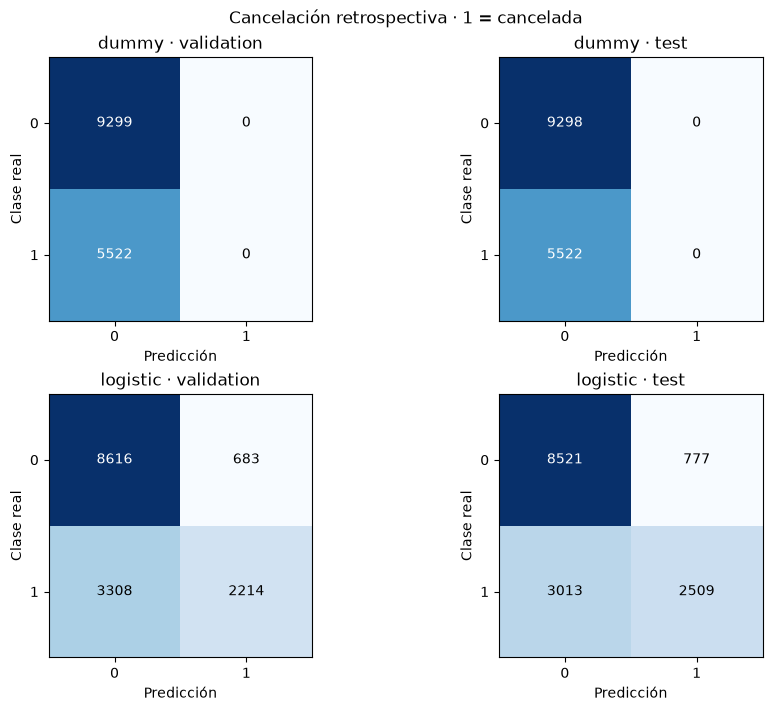

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(9, 7), layout="constrained")
for row_index, model_name in enumerate(["dummy", "logistic"]):
    for column_index, split in enumerate(["validation", "test"]):
        ax = axes[row_index, column_index]
        matrix = results["classification"]["metrics"][model_name][split][
            "confusion_matrix"
        ]
        ax.imshow(matrix, cmap="Blues")
        threshold = max(max(row) for row in matrix) / 2
        for i in range(2):
            for j in range(2):
                ax.text(
                    j,
                    i,
                    str(matrix[i][j]),
                    ha="center",
                    va="center",
                    color="white" if matrix[i][j] > threshold else "black",
                )
        ax.set(
            xticks=[0, 1],
            yticks=[0, 1],
            xlabel="Predicción",
            ylabel="Clase real",
            title=f"{model_name} · {split}",
        )
fig.suptitle("Cancelación retrospectiva · 1 = cancelada")
fig.savefig(output_dir / "confusion.svg", bbox_inches="tight")
plt.show()
plt.close(fig)

## 9. Exportaciones, manifiesto y contraste opcional

Todo lo nuevo se escribe en `outputs/notebook_phase2` (fuente, calidad, limpieza, métricas, manifiesto y matriz) y `data/processed/notebook_phase2` (cleaned y seis particiones). El CSV no se modifica. Se registran versiones, semilla, huella raw, reglas, poblaciones, predictores, estadísticas train y tamaños/histogramas de grupos.

Si existe el JSON canónico **solo se lee** para comparar; su ausencia no impide ejecutar. La referencia auditada tiene SHA-256 `99b5e3ffafbeb2540a4e6d245fc43ab33d31130cf146cbf2de1d94c40dbb0a6c`. Se comparan tareas completas (splits, métricas y diagnósticos), no se copian resultados. Puede haber redondeo entre bibliotecas/plataformas; cualquier diferencia se hace visible, no se oculta.

In [17]:
canonical_path = root / "outputs/phase2.json"
comparison = {"available": canonical_path.exists()}
if canonical_path.exists():
    reference = json.loads(canonical_path.read_text(encoding="utf-8"))
    comparison.update(
        {
            "reference_sha256": hashlib.sha256(canonical_path.read_bytes()).hexdigest(),
            "same_seed": reference["seed"] == SEED,
            "tasks_equal": {
                task: reference["tasks"][task] == results[task] for task in results
            },
            "metrics_equal": {
                task: reference["tasks"][task]["metrics"] == results[task]["metrics"]
                for task in results
            },
            "splits_equal": {
                task: reference["tasks"][task]["splits"] == results[task]["splits"]
                for task in results
            },
        }
    )
print("Contraste canónico:", comparison)
write_json(output_dir / "comparison.json", comparison)
assert (
    hashlib.sha256((raw_dir / "hotel_bookings.csv").read_bytes()).hexdigest()
    == raw_hash
)
manifest = {
    "python": sys.version.split()[0],
    "seed": SEED,
    "raw_sha256": raw_hash,
    "versions": {
        name: version(name)
        for name in [
            "polars",
            "numpy",
            "scipy",
            "scikit-learn",
            "matplotlib",
            "kagglehub",
        ]
    },
    "source": DATASET,
    "license": "CC BY 4.0",
    "original_download_date": None,
    "rules": audit["rules"],
    "input_rows": raw.height,
    "retained_rows": cleaned.height,
    "populations": {
        task: result["population_rows"] for task, result in results.items()
    },
    "artifacts": [
        "source.json",
        "quality.json",
        "cleaning.json",
        "phase2.json",
        "comparison.json",
        "confusion.svg",
    ],
    "details": "phase2.json: splits, group histograms, X overlap, predictors, train statistics, imbalance and metrics; cleaning.json: rejected row IDs and reasons",
    "interpretation": "Retrospective snapshot day before arrival; ADR conditional on non-cancellation, not initial quote; no causality or future validation",
}
write_json(output_dir / "manifest.json", manifest)
print("Exportación terminada; original intacto.")

Contraste canónico: {'available': True, 'reference_sha256': '99b5e3ffafbeb2540a4e6d245fc43ab33d31130cf146cbf2de1d94c40dbb0a6c', 'same_seed': True, 'tasks_equal': {'classification': True, 'regression': True}, 'metrics_equal': {'classification': True, 'regression': True}, 'splits_equal': {'classification': True, 'regression': True}}
Exportación terminada; original intacto.


## 10. Conclusiones y límites

1. El CSV actual pasa de **119390 a 118564** reservas: **826** descartes distintos, repetidos conservados. Las dos features quedan trazables y la imputación no pierde adultos conocidos.
2. La partición ponderada reserva aproximadamente **75/12.5/12.5 % de filas**, con repetidos representados en los tres splits y cero huellas originales cruzadas. La masa repetida y perfiles X se diagnostican, no se confunden con clientes independientes.
3. En esta referencia, la lineal reduce MAE/RMSE frente a la media; logística supera al Dummy, pero recall sigue limitado. Leer los valores recién calculados, no tomar estas observaciones como certificación de rendimiento futuro.
4. ADR no es cotización inicial: la regresión solo cubre **no canceladas**, con sesgo de selección. Dos hoteles históricos, faltantes, colas y posibles grupos comerciales limitan generalización. No hay moneda demostrada, inferencia causal ni validación prospectiva.

**Cobertura 3.2:** ausencia/outliers justificados (3–4), dos derivados (5), partición estratificada/desbalance (6), encoding/escalado train-only (7), baselines (8). La adquisición usa red únicamente si falta raw. El notebook se puede mover junto al CSV y ejecutar con dependencias de terceros, sin ningún módulo o resultado del repositorio.